# Planta Física: genetic algorithms through four decisions

MA2015.202 · March 2025 · One cumulative notebook.

We explain the supplied model, follow one generation and compare two small configurations. Keep your team's calculations, code and interpretation in this notebook.

## 1. We define the problem

We allocate a fraction of treated water to each building to reduce potable-water use. We use aggregate March 2025 demands: Aulas 1 = 847, Biblioteca = 462, Cedetec = 284.21 and Aulas 2 = 683 m³. We retain this order. The four source records have no imputation, zero or possible-anomaly flags.

We adopt 1,410 m³ as **teaching capacity** from the instructor's calibration; it is not a partner-confirmed capacity. We also treat each building's reuse limit as a teaching assumption.

We encode $k=(k_1,k_2,k_3,k_4)$ using integers: $k_1,k_2,k_4\in\{0,\ldots,8\}$ and $k_3\in\{0,\ldots,6\}$. We interpret $x_i=k_i/10$. For example, gene 6 represents 60% reuse. There are $9\times9\times7\times9=5103$ combinations; we explore some using the genetic algorithm.

In [27]:
import numpy as np

BUILDINGS = ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
DEMAND = np.array([847.0, 462.0, 284.21, 683.0])  # m3, March 2025
LIMITS = np.array([8, 8, 6, 8])  # integer levels; fractions = levels / 10
CAPACITY = 1410.0  # m3; teaching assumption, not confirmed plant capacity

## 2. We calculate water volumes and fitness

We define treated water $T=\sum_iD_i k_i/10$, potable water $P=\sum_iD_i-T$ and excess capacity $E=\max(0,T-C)$. We minimize $P$ subject to the gene domains and $T\le C$.

We rank candidates using $F=P/\sum D_i$ when they are feasible and $F=1+E/C$ when they exceed capacity. **Lower fitness is better.** A feasible candidate has $F\le1$; an infeasible candidate has $F>1$. We use a numerical tolerance of $10^{-8}$ m³.

Before running the code, calculate $k=(6,6,6,6)$ by hand: $T=0.6(2276.21)=1365.726$, $P=910.484$, $E=0$, $F=0.4$. Explain why capacity is satisfied and identify each result's unit.

In [28]:
def evaluate(genes: np.ndarray) -> dict:
    """Return physical totals and fitness (lower is better) for four integer genes."""
    genes = np.asarray(genes)
    if genes.shape != (4,) or not np.issubdtype(genes.dtype, np.integer):
        raise ValueError("Expected four integer genes in building order.")
    if np.any(genes < 0) or np.any(genes > LIMITS):
        raise ValueError("Genes outside the allowed building domains.")
    treated = float(np.sum(DEMAND * genes / 10))
    potable = float(np.sum(DEMAND) - treated)
    excess = max(0.0, treated - CAPACITY)
    feasible = excess <= 1e-8  # numerical tolerance in m3
    fitness = potable / float(np.sum(DEMAND)) if feasible else 1 + excess / CAPACITY
    return dict(treated=treated, potable=potable, excess=excess,
                feasible=feasible, fitness=fitness)

## Manual calculations

### Candidate:
k=(8, 4, 3, 6). I chose a plan that would be feasable and as I tried to guess the values of that could fit better inside of the genes' domains. It is not the best, but I chose it in order to practice the evaluation. All genes are inside their domains (k_1 ≤ 8, k_2 ≤ 8,k_3 ≤ 6 k_4 ≤ 8).

| Building | D_i (m^3) | k_i | x_i = k_i/10 | T_i = D_i*x_i (m^3) | P_i = D_i − T_i (m^3) |
|---|---|---|---|---|---|
| Aulas 1 | 847 | 8 | 0.8 | 847 × 0.8 = 677.600 | 847 − 677.6 = 169.400 |
| Biblioteca | 462 | 4 | 0.4 | 462 × 0.4 = 184.800 | 462 − 184.8 = 277.200 |
| Cedetec | 284.21 | 3 | 0.3 | 284.21 × 0.3 = 85.263 | 284.21 − 85.263 = 198.947 |
| Aulas 2 | 683 | 6 | 0.6 | 683 × 0.6 = 409.800 | 683 − 409.8 = 273.200 |

### Totals:
- T = 677.6 + 184.8 + 85.263 + 409.8 = 1357.463 m^3
- P = 169.4 + 277.2 + 198.947 + 273.2 = 918.747 m^3
- E = max(0, 1357.463 − 1410) = max(0, −52.537) = 0 m^3
- Feasible: yes, since T ≤ 1410 (52.537 m^3 of capacity left).
- Because it is feasible, F = P / Q = 918.747 / 2276.21 = 0.40363 (rounded to 5 decimals).

### Checks:
- T_i + P_i = D_i holds in all four buildings (e.g. 85.263 + 198.947 = 284.21).
- T + P = 1357.463 + 918.747 = 2276.21 = Q.

## Maximum chromosome: (8, 8, 6, 8)

Every gene is at the top of its domain, so the chromosome is valid.

| Building | D_i (m^3) | k_i | T_i (m^3) |
|---|---|---|---|
| Aulas 1 | 847 | 8 | 847 × 0.8 = 677.600 |
| Biblioteca | 462 | 8 | 462 × 0.8 = 369.600 |
| Cedetec | 284.21 | 6 | 284.21 × 0.6 = 170.526 |
| Aulas 2 | 683 | 8 | 683 × 0.8 = 546.400 |

- T = 677.6 + 369.6 + 170.526 + 546.4 = 1764.126 m^3
- P = 2276.21 − 1764.126 = 512.084 m^3
- E = 1764.126 − 1410 = 354.126 m³
- Feasible: no, because T > C.
- Since T > C, the penalized branch is applied: F = 1 + E/C = 1 + 354.126/1410 = 1.25115.

### Interpretation:
Domains only limit each gene separately, while the capacity, limits the sum of the four volumes. Each building is within its own limit, however when e take into consideration the whole picture, together they ask the plant for 354.126 m^3 more treated water per month than the assumed 1410 m^3 capacity. This plan has the lowest potable use of all, but it is not possible for it top be supplied, so it gets F > 1 and loses against any feasible plan.


In [ ]:
my_genes = np.array([8, 4, 3, 6], dtype=int)
my_eval = evaluate(my_genes)
my_eval

#I used my_genes and my_eval instead of genes and result because we use them again later

{'treated': 1357.4630000000002,
 'potable': 918.7469999999998,
 'excess': 0.0,
 'feasible': True,
 'fitness': 0.4036301571471876}

In [30]:
print("T:", 1357.463, my_eval["treated"], abs(1357.463 - my_eval["treated"]))
print("P:", 918.747, my_eval["potable"], abs(918.747 - my_eval["potable"]))
print("E:", 0.0, my_eval["excess"], abs(0.0 - my_eval["excess"]))
print("F:", 0.40363, my_eval["fitness"], abs(0.40363 - my_eval["fitness"]))
print("feasible:", True, my_eval["feasible"])

T: 1357.463 1357.4630000000002 2.2737367544323206e-13
P: 918.747 918.7469999999998 1.1368683772161603e-13
E: 0.0 0.0 0.0
F: 0.40363 0.4036301571471876 1.5714718759607393e-07
feasible: True True


| Quantity | Manual | Evaluator | Difference |
|---|---|---|---|
| T (m^3) | 1357.463 | 1357.463000000002 | 2e-13 |
| P (m^3) | 918.747 | 918.74699999998 | 2e-13 |
| E (m^3) | 0 | 0.0 | 0 |
| F | 0.40363 | 0.40363016 | 1.6e-7 |
| Feasible | Yes | True | agree |

The difference between T and P is around 1e-13 because of how computers store decimals. F differs by about 1.6e-7 because my manual value was rounded to 5 decimals.

Check three candidates: zero reuse, uniform 60% reuse and the maximum levels in each domain. Distinguish valid genes from compliance with capacity. The keys `treated`, `potable`, `excess`, `feasible` and `fitness` correspond to $T$, $P$, $E$, feasibility and $F$.

In [31]:
cases = [np.zeros(4, dtype=int), np.array([6, 6, 6, 6]), LIMITS.copy()]
for genes in cases:
    print(genes, evaluate(genes))
assert np.isclose(evaluate(cases[1])["potable"], 910.484)
assert evaluate(cases[1])["feasible"]
assert not evaluate(cases[2])["feasible"]

[0 0 0 0] {'treated': 0.0, 'potable': 2276.21, 'excess': 0.0, 'feasible': True, 'fitness': 1.0}
[6 6 6 6] {'treated': 1365.7259999999999, 'potable': 910.4840000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.4000000000000001}
[8 8 6 8] {'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}


We interpret the maximum plan: it uses 1764.126 m³ of treated water, exceeds capacity by 354.126 m³ and obtains $F>1$. Although it reduces potable-water use further, we reject it as infeasible. Keep the manual calculation and your team's explanation as Research evidence.

## 3. We generate a population

A population is a list of candidates. We sample each gene within its domain, including both endpoints. Sampling does not guarantee compliance with capacity: fitness also ranks infeasible candidates. We fix the seed to reproduce this demonstration.

In [32]:
def random_individual(rng: np.random.Generator) -> np.ndarray:
    """Sample one valid discrete chromosome; capacity is checked by evaluate."""
    return rng.integers(0, LIMITS + 1)

rng_demo = np.random.default_rng(42)
population_demo = [random_individual(rng_demo) for _ in range(4)]
for genes in population_demo:
    print(genes, evaluate(genes)["fitness"])

[0 6 4 3] 0.7382561362967388
[3 7 0 6] 0.5662526744017468
[1 0 3 8] 0.6852825530157587
[6 6 5 7] 0.38248008751389373


## 4. We select parents through tournaments

We sample two distinct candidates and choose the one with lower $F$. We repeat the process to select another parent; the same individual can win several tournaments. Selection favors lower fitness without always sorting the entire population. We return a copy to protect the original.

In [33]:
def tournament(population: list, rng: np.random.Generator) -> np.ndarray:
    """Return an independent copy of the better of two sampled individuals."""
    indices = rng.choice(len(population), size=2, replace=False)
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    return winner.copy()

parent_a = tournament(population_demo, rng_demo)
parent_b = tournament(population_demo, rng_demo)
print(parent_a, parent_b)

[3 7 0 6] [3 7 0 6]


## 5. We combine information through one-point crossover

We choose a cut between gene positions and combine the beginning of the first parent with the end of the second. We preserve each building's position. For parents $(6,6,6,6)$ and $(8,2,4,3)$ with cut 2, we obtain $(6,6,4,3)$. Crossover preserves gene domains but can produce excess capacity.

In [34]:
def crossover(parent_a: np.ndarray, parent_b: np.ndarray,
              rng: np.random.Generator) -> np.ndarray:
    """Create one child using a cut between genes and preserving their positions."""
    cut = int(rng.integers(1, len(LIMITS)))
    return np.concatenate((parent_a[:cut], parent_b[cut:]))

child_demo = crossover(parent_a, parent_b, rng_demo)
print(child_demo, evaluate(child_demo))

[3 7 0 6] {'treated': 987.3, 'potable': 1288.91, 'excess': 0.0, 'feasible': True, 'fitness': 0.5662526744017468}


## 6. We introduce variation through mutation

We apply the probability to **each gene**, rather than to the whole chromosome. Each selected gene increases or decreases by one valid level. At zero we can only increase; at the maximum we can only decrease. With $p=0.25$ and four genes, we expect one selected gene per child on average, rather than exactly one. Mutation can improve or worsen fitness.

In [35]:
def mutate(child: np.ndarray, probability: float,
           rng: np.random.Generator) -> np.ndarray:
    """Independently move each selected gene one valid discrete step."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            result[i] = rng.choice(neighbors)
    return result

mutated_demo = mutate(child_demo, 0.25, rng_demo)
print(child_demo, mutated_demo, evaluate(mutated_demo))

[3 7 0 6] [3 7 0 7] {'treated': 1055.6, 'potable': 1220.6100000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.5362466556249205}


## 7. We replace the population and preserve one elite

We copy the best individual without changing it and fill the remaining positions with children. We keep the population size constant. Elitism prevents loss of the best fitness value; it does not establish that we have found the optimum. With an independent copy, mutating a child does not change its parent or the elite.

In [36]:
def next_generation(population: list, probability: float,
                    rng: np.random.Generator) -> list:
    """Preserve one independent elite and replace all other individuals."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover(parent_a, parent_b, rng)
        replacement.append(mutate(child, probability, rng))
    return replacement

replacement_demo = next_generation(population_demo, 0.25, rng_demo)
print(min(evaluate(x)["fitness"] for x in population_demo))
print(min(evaluate(x)["fitness"] for x in replacement_demo))

0.38248008751389373
0.38248008751389373


## 8. We complete the cycle

We initialize, evaluate and repeat selection, crossover, mutation and replacement for a fixed number of generations. We record the initial best $F$ and the best value after each generation. With 20 generations, we obtain 21 values, including initialization. We do not expect improvement at every step.

In [37]:
def run_ga(population_size: int = 20, generations: int = 20,
           mutation_probability: float = 0.25, seed: int = 42) -> dict:
    """Run a small canonical GA and retain the best fitness at each generation."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation(population, mutation_probability, rng)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history))

## 9. Run the baseline and a mutation variation

Use 20 individuals, 20 generations and seed 42. In the variation, change only the per-gene mutation probability from 0.25 to 0.50. Keep the data, gene domains, capacity and all other parameters fixed. This comparison describes two executions; it does not establish general superiority of either configuration.

This demonstration supplies the same-code comparison used in Final. For Development, separately preserve the baseline, make a substantive change to one operator, and compare the baseline and your operator variant with $p_m=0.25$ in both runs.

In [38]:
CONFIG = dict(population_size=20, generations=20, mutation_probability=0.25, seed=42)
baseline = run_ga(**CONFIG)
variant_config = {**CONFIG, "mutation_probability": 0.50}
variant = run_ga(**variant_config)
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    print(label, "genes =", result["genes"], "fractions =", result["genes"] / 10)
    print(result["metrics"])

p=0.25 genes = [7 4 3 8] fractions = [0.7 0.4 0.3 0.8]
{'treated': 1409.363, 'potable': 866.847, 'excess': 0.0, 'feasible': True, 'fitness': 0.38082909749100474}
p=0.50 genes = [5 7 4 8] fractions = [0.5 0.7 0.4 0.8]
{'treated': 1406.984, 'potable': 869.2260000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.3818742558902738}


## 10. We visualize and interpret

We read the horizontal axis as generation and the vertical axis as best fitness. A decrease represents improvement; a plateau means we retain the best value. We always connect the plot to feasibility and water volumes. A descending curve alone does not establish physical validity.

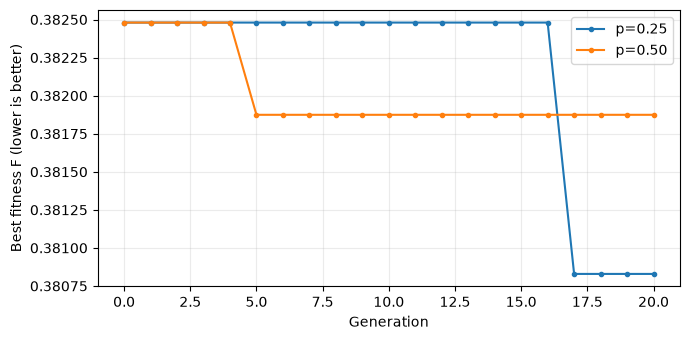

In [39]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    ax.plot(range(len(result["history"])), result["history"], marker=".", label=label)
ax.set(xlabel='Generation', ylabel='Best fitness F (lower is better)')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

Keep your team's interpretation in a text cell: identify the changed parameter; compare best $F$, potable-water use and feasibility; explain a plateau or improvement; and delimit what two executions support. If the results match, explain that agreement. The mutation variation does not need to outperform the baseline.

## 11. Check reproduction

Repeat the baseline with the same seed and check that genes and history match. Restart the kernel and run the notebook from top to bottom to rule out dependence on previous executions. This repetition is a technical check, rather than a third experimental configuration.

In [40]:
repeated = run_ga(**CONFIG)
np.testing.assert_array_equal(baseline["genes"], repeated["genes"])
np.testing.assert_array_equal(baseline["history"], repeated["history"])
assert np.all(np.diff(baseline["history"]) <= 1e-12)
print('Reproduction and elitism checked.')

Reproduction and elitism checked.


## 12. Keep evidence in the same notebook

- **Research (15%)**: A1 formulation and assumptions (60/100); A2 hand calculation and comparison with the evaluator (40/100).
- **Development (15%)**: B1 functional cycle and justified substantive modification of one operator (70/100); B2 reproducibility and controlled baseline/variant comparison (30/100). Use $p_m=0.25$ for both versions.
- **Final (30%)**: C1 explanation of one generation (40/100); C2 same-code comparison of mutation probabilities 0.25/0.50 and its plot (35/100); C3 physical interpretation and model limitations (25/100).

For Final, retain earlier sections and add your team's explanation. Identify the supplied baseline and any team changes. If you still have only the baseline, identify it as unmodified and complete the Final analysis; the Development penalty will not be applied again. Keep the supplied environment files beside the notebook. The written team code examination will contribute 10% and the individual article examination will contribute 30%. Consult the [guide](challenge_guide_planta_fisica.pdf) and the detailed instructions in Canvas for performance levels and dates.

## Provenance and environment

We use the four March 2025 records from the supplied water-consumption data and the instructor-calibrated teaching limits. Notebook metadata retains the records and source hashes. The monthly case and code are self-contained.

With Python 3.12-3.14 and the supplied environment files, prepare the environment with `uv sync --locked` and open Jupyter with `uv run jupyter lab`. NumPy performs the calculations and Matplotlib draws the plot. Results describe this teaching model; they do not establish a validated hydraulic or sanitary recommendation.